In [46]:
import numpy as np
import sionna.rt as rt
from jupyter_server.prometheus import metrics

practice_scene = rt.load_scene()

In [47]:
tx = rt.Transmitter(
    name = "test_tx",
    position = [0, 0, 2]
)

practice_scene.add(tx)

In [48]:
rx_a = rt.Receiver(
    name = "rx_a",
    position = [5, 0, 1]
)

rx_b = rt.Receiver(
    name = "rx_b",
    position = [10, 0, 1]
)

practice_scene.add(rx_a)
practice_scene.add(rx_b)

rec_a = practice_scene.get("rx_a")
rec_a.position = [7, 0, 1]

rec_b = practice_scene.get("rx_b")
practice_scene.remove(rec_b.name)

print(rx_a.position)
print(rx_a.name)
print(practice_scene.get("rx_b"))

rx_b.position = [12, 0, 1]

practice_scene.add(rx_b)

print(practice_scene.receivers.keys())
print(practice_scene.get("rx_b").position)

[[7, 0, 1]]
rx_a
None
dict_keys(['rx_a', 'rx_b'])
[[12, 0, 1]]


In [49]:
practice_scene.frequency = 3.5e9

practice_scene.tx_array = rt.PlanarArray(
    num_rows = 1,
    num_cols = 1,
    vertical_spacing = 0.5,
    horizontal_spacing = 0.5,
    pattern = "iso",
    polarization = "V"
)

practice_scene.rx_array = rt.PlanarArray(
    num_rows=1,
    num_cols=1,
    vertical_spacing=0.5,
    horizontal_spacing=0.5,
    pattern="iso",
    polarization= "V"
)

practice_scene.all_set(radio_map=False)

In [50]:
practice_solver = rt.PathSolver()

practice_paths = practice_solver(
    scene = practice_scene,
    max_depth=0
)

print(list(practice_scene.receivers.keys()))
print(practice_paths.valid)
delays = np.array(practice_paths.tau)
print(delays.shape)

delays_ns = delays * 1e+9
print(delays_ns[0, 0, 0])
print(delays_ns[1, 0, 0])

['rx_a', 'rx_b']
[[[True]],
 [[True]]]
(2, 1, 1)
23.586542
40.166435


In [51]:
tx_position = np.array(practice_scene.get("test_tx").position)
rx_position = np.array(practice_scene.get("rx_a").position)

distance = np.linalg.norm(rx_position - tx_position)

delay_for_first_receiver_ns = (distance / 299_792_458) * 1e+9
print("My value:", delay_for_first_receiver_ns, ", value calculated by sionna:", delays_ns[0, 0, 0])

rx_b_position = np.array(practice_scene.get("rx_b").position)

distance_second = np.linalg.norm(rx_b_position - tx_position)

delay_for_second_receiver_ns = (distance_second / 299_792_458) * 1e+9
print("My second value:", delay_for_second_receiver_ns, ", value calculated by sionna:", delays_ns[1, 0, 0])



My value: 23.586544 , value calculated by sionna: 23.586542
My second value: 40.16644 , value calculated by sionna: 40.166435


In [52]:
first_matches = np.isclose(
    delays_ns[0, 0, 0],
    delay_for_first_receiver_ns,
    rtol = 1e-6,
    atol = 0.0
)


second_matches = np.isclose(
    delays_ns[1, 0, 0],
    delay_for_second_receiver_ns,
    rtol = 1e-6,
    atol = 0.0
)


false_second_matches = np.isclose(
    delays_ns[1, 0, 0] + 1,
    delay_for_second_receiver_ns,
    rtol = 1e-6,
    atol = 0.0
)

assert first_matches, "Затримка rx_a не збігається з еталоном"
assert second_matches, "Затримка rx_b не збігається з еталоном"

print("All reviews are done")

All reviews are done


In [53]:
practice_scene.frequency = 3.5e9

paths_35 = practice_solver(
    scene = practice_scene,
    max_depth = 0
)

a_35, tau_35 = paths_35.cir(
    normalize_delays=False,
    out_type="numpy"
)

gains_35 = np.abs(a_35) ** 2

practice_scene.frequency = 7e9

paths_7 = practice_solver(
    scene = practice_scene,
    max_depth = 0
)

a_7, tau_7 = paths_7.cir(
    normalize_delays = False,
    out_type = "numpy"
)

gains_7 = np.abs(a_7) ** 2

print(tau_35 * 1e+9)
print(tau_7 * 1e+9)

print(gains_7 / gains_35)

[[[23.586542]]

 [[40.166435]]]
[[[23.586542]]

 [[40.166435]]]
[[[[[[0.24999997]]]]]




 [[[[[0.24999996]]]]]]


In [54]:
coverage_scene = rt.load_scene()
coverage_scene.frequency = 2e9

coverage_scene.tx_array = rt.PlanarArray(
    num_cols=1,
    num_rows=1,
    pattern="iso",
    polarization = "V"
)

coverage_scene.rx_array = coverage_scene.tx_array

coverage_tx = rt.Transmitter(
    name = "coverage_tx",
    position=[20, 0, 10],
    power_dbm=30
)

coverage_scene.add(coverage_tx)

In [55]:
map_solver = rt.RadioMapSolver()

radio_map = map_solver(
    scene=coverage_scene,
    max_depth=0,
    samples_per_tx=1_000_000,
    center=[0, 0, 1.5],
    orientation=[0,0,0],
    size = [100, 100],
    cell_size=[2, 2]
)

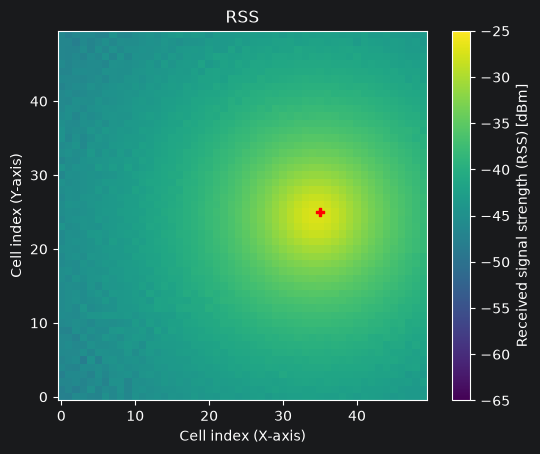

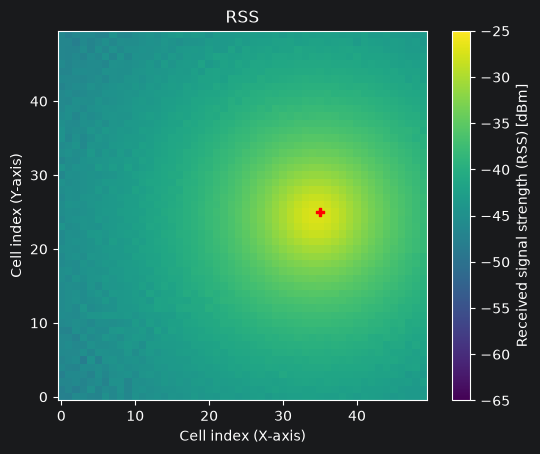

In [56]:
radio_map.show(metric = "rss", vmin = -65, vmax = -25)

In [57]:
street_scene = rt.load_scene(
    rt.scene.simple_street_canyon,
    merge_shapes=False
)

street_scene.frequency = 3.5e9

street_scene.tx_array = rt.PlanarArray(
    num_rows=1,
    num_cols=1,
    pattern="iso",
    polarization = "V"
)
street_scene.rx_array = street_scene.tx_array

street_tx = rt.Transmitter(
    name = "street_tx",
    position= [0, 0, 10],
    power_dbm=30
)

street_scene.add(street_tx)

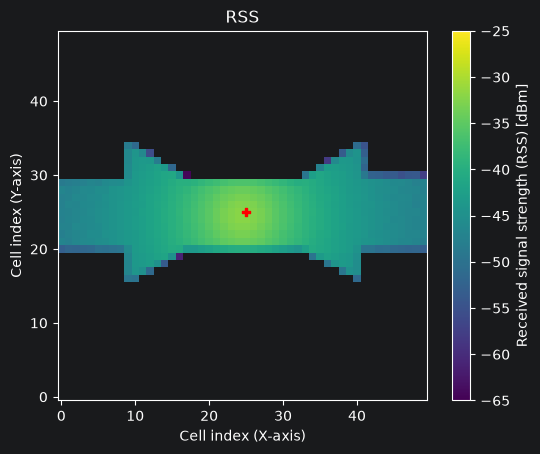

In [58]:
street_map = map_solver(
    scene=street_scene,
    max_depth=0,
    refraction=False,
    samples_per_tx=1_000_000,
    center=[0,0,1.5],
    orientation=[0,0,0],
    size = [100, 100],
    cell_size=[2, 2]
)

street_map.show(metric = "rss", vmin = -65, vmax = -25)

street_scene.preview(radio_map=street_map, rm_metric="rss", rm_vmin=-65, rm_vmax=-25)

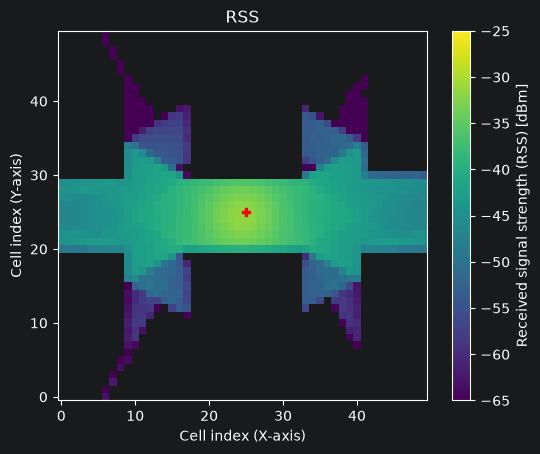

In [59]:
street_map_reflections = map_solver(
    scene=street_scene,
    max_depth=1,
    los=True,
    specular_reflection=True,
    diffuse_reflection=False,
    refraction=False,
    samples_per_tx=1_000_000,
    center=[0,0,1.5],
    orientation=[0,0,0],
    size=[100,100],
    cell_size=[2,2]
)

street_map_reflections.show(
    metric = "rss",
    vmin = -65,
    vmax = -25
)

street_scene.preview(
    radio_map=street_map_reflections,
    rm_metric= "rss",
    rm_vmin=-65,
    rm_vmax=-25
)

In [60]:
rss_before = np.array(street_map.rss)
rss_after = np.array(street_map_reflections.rss)

mask = (rss_before > 0) & (rss_after > 0)

change_db = 10 * np.log10(rss_after[mask] / rss_before[mask])

print(change_db.max())
print(change_db.min())
print(change_db.mean())

7.118158
0.034812372
0.81189615


In [61]:
new_coverage  = (rss_before == 0) & (rss_after > 0)

count = np.count_nonzero(new_coverage)

sum_area_in_square_m = count * 4
print(sum_area_in_square_m)

1056


In [62]:
threshold_dbm = -60
threshold_w = 1e-3 * 10 ** (threshold_dbm / 10)

threshold_mask_before = (rss_before >= threshold_w)
threshold_mask_after = (rss_after >= threshold_w)

count_before = np.count_nonzero(threshold_mask_before)
count_after = np.count_nonzero(threshold_mask_after)

area_by_dbm_before = count_before * 4
area_by_dbm_after = count_after * 4

print(area_by_dbm_before)
print(area_by_dbm_after)

print("Area expands in", area_by_dbm_after - area_by_dbm_before, "square meters")

2388
3032
Area expands in 644 square meters


In [68]:
thresholds_dbm = np.array([-70, -65, -60, -55, -50, -45, -40])
thresholds_w = 1e-3 * 10 ** (thresholds_dbm / 10)

areas_before = []
areas_after = []

for threshold_w in thresholds_w:
    mask_before = (rss_before >= threshold_w)
    mask_after = (rss_after >= threshold_w)

    area_before = np.count_nonzero(mask_before) * 4
    area_after = np.count_nonzero(mask_after) * 4

    areas_before.append(area_before)
    areas_after.append(area_after)

print(areas_before[2])
print(areas_after[2])

2388
3032
